# 08 — Sensibilidade e concentração

**Para que serve este notebook.** A escada do projeto (`docs/plano_projeto.md`) dá um prêmio anual de **R$ 368,7 mil** para o mercado de seguro-garantia dos cartórios de MG. A partir do passo 5, esse número depende de **suposições sem fonte pública**: a chance de o titular não ter bens suficientes, quanto do passivo fica descoberto, quantos escolhem o seguro e a taxa cobrada. Este notebook responde **quão certo é esse número** e **o que mais mexe nele**:

1. **Tornado:** cada premissa sozinha do mínimo ao máximo. Qual pesa mais?
2. **Monte Carlo:** todas as suposições sorteadas ao mesmo tempo. Qual é a faixa realista do prêmio?
3. **Passivo:** o passivo (passo 4) muda se a gente tratar de outro jeito os salários ausentes e os municípios com poucos empregados?
4. **Concentração:** quanto do passivo e da receita está nos maiores cartórios?
5. **Receita líquida do Prov. 213:** a norma manda classificar pela receita **depois** de tirar os repasses obrigatórios; o painel usa a arrecadação bruta. Quanto isso muda o universo de obrigadas?

**Como os métodos foram escolhidos.** Os testes **T5, T6 e T7** (`docs/qa/analises/testes_metodos.md`) escolheram os métodos. Aqui usamos os vencedores, com as **funções do modelo** (`src/model`, `src/motor.py`) e a semente de `config/analise.yaml` (20261022; os testes usaram 42).

**Regra:** tudo aqui é **sensibilidade**, rotulada como tal. **Nenhum dos 10 números do painel muda** (as decisões D-015 e D-022 continuam na base).

**Termos usados** (explicados onde aparecem pela primeira vez): premissa e suposição, tornado, Monte Carlo, distribuição triangular, percentil (P5, P50, P95), curva de Lorenz, índice de Gini, encolhimento (Bayes empírico).

**Dados:** banco do pipeline (carga de 19/10/2026; regra de classe v2; cenário do STF "mantém"), premissas v2 (`config/premissas/premissas_v002.yaml`), RAIS 2025, CSV do BI do CNJ (exportado em 18/10/2026) e o texto do Prov. 213 no bronze (coletado em 17/10/2026). Os gráficos também vão em PNG para `docs/qa/analises/`.

In [1]:
import json
import sys
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from src import estado
from src.analise import config, dados, estatistica as est, graficos as g, sensibilidade as se
from src.model import simulador
from src.model.passivo import passivo_vinculos
from src.motor import Insumos, calcular_serventias, peso_indeterminada, premissas_nivel, resumo_mercado
from src.notebooks import conectar
from src.transform.gold import carregar_insumos

g.estilo()
cfg = config()
SEMENTE, N = cfg["semente"], cfg["sensibilidade"]["sorteios"]
con = conectar()
semente_premissas = estado.ler_semente()                       # config/premissas/premissas_v002.yaml
cenarios = yaml.safe_load((raiz / "config/cenarios_stf.yaml").read_text(encoding="utf-8"))
limites = yaml.safe_load((raiz / "config/regras_classificacao.yaml").read_text(encoding="utf-8"))["versoes"]["v2"]["limites"]
peso = con.execute("SELECT peso_classe_indeterminada_base FROM gold.execucao WHERE regra_classe = 'v2'").fetchone()[0]
p = premissas_nivel(semente_premissas, "base", peso)
sv = dados.serventias(con)
totais = simulador.totais(sv)
oficial = con.execute("""SELECT nivel, n_universo, passivo_todas, passivo_universo, n_deficit, valor_descoberto,
    mercado_importancia_segurada, mercado_premio_emitido FROM gold.fato_mercado_uf
    WHERE regra_classe = 'v2' AND cenario_stf = 'mantem'""").df().set_index("nivel")
base = simulador.resumo_por_totais(totais, p, cenarios, "mantem")
print(f"Base pelo modelo: déficit {g.reais(base['valor_descoberto'])}, IS {g.reais(base['mercado_importancia_segurada'])}, "
      f"prêmio {g.reais(base['mercado_premio_emitido'])} (painel: {g.reais(oficial.loc['base', 'mercado_premio_emitido'])}).")
print(f"Faixa oficial do prêmio (todas as premissas no mínimo / no máximo): {g.reais(oficial.loc['min', 'mercado_premio_emitido'])} "
      f"a {g.reais(oficial.loc['max', 'mercado_premio_emitido'])}. Semente: {SEMENTE}; sorteios: {g.num(N)}.")
t7 = json.loads((raiz / "docs/qa/analises/testes_metodos_resultados.json").read_text(encoding="utf-8"))["T7_incerteza_premio"]

Base pelo modelo: déficit R$ 36,9 mi, IS R$ 18,4 mi, prêmio R$ 368,7 mil (painel: R$ 368,7 mil).
Faixa oficial do prêmio (todas as premissas no mínimo / no máximo): R$ 24,7 mil a R$ 2,8 mi. Semente: 20261022; sorteios: 200.000.


A linha acima reproduz os números 7, 8 e 9 do painel (déficit de R$ 36,9 mi, IS de R$ 18,4 mi e prêmio de R$ 368,7 mil) e a faixa oficial de mínimo a máximo, o que confirma que estamos usando o mesmo modelo.

**Premissa × suposição.** Toda premissa do modelo tem mínimo, base e máximo em `config/premissas/premissas_v002.yaml`. Algumas têm fonte (lei, dado da SUSEP); as seis dos passos 5 a 8 são **suposições** (`fonte: suposição`), aprovadas pelo autor em 18/10/2026 (D-016).

## 1. Tornado: qual premissa mais mexe no prêmio?

**A pergunta.** Se só uma premissa estivesse errada, quanto o prêmio mudaria?

**O método.** O **tornado** põe uma premissa no mínimo e depois no máximo, com todas as outras no valor base, e anota o prêmio. A distância entre os dois é a **amplitude**. As barras ficam em ordem da maior para a menor amplitude, e o desenho lembra um funil (daí o nome).

Exemplo: a taxa do seguro vai de 1% a 3,5% ao ano, com base em 2%. Como o prêmio = importância segurada (IS) × taxa, e a IS da base é R$ 18,4 mi, o prêmio vai de 18,4 mi × 1% = R$ 184 mil a 18,4 mi × 3,5% = R$ 645 mil.

Entram dois grupos:
- as **seis suposições** do teste T7 (passos 5 a 8): o prêmio sai de `simulador.resumo_por_totais`, com o passivo fixo no nível base;
- as **premissas do passivo e do universo** que têm mínimo diferente do máximo (férias vencidas, INSS sobre o aviso, FAP, peso das serventias de classe indeterminada e se intervenção e diligência entram no universo): o modelo inteiro é refeito, serventia por serventia (`motor.calcular_serventias`).

**Por que este método.** É o do teste T7: mostra direto qual premissa vale a pena pesquisar melhor.

,rotulo,grupo,valor_min,valor_base,valor_max,premio_no_min,premio_no_max,amplitude,no T7 (R$ mil)
0,Taxa do seguro,suposição (passos 5 a 8),0.01,0.02,0.035,"R$ 184,4 mil","R$ 645,3 mil","R$ 460,9 mil",184 – 645
1,Parte do déficit que escolhe seguro,suposição (passos 5 a 8),0.25,0.5,0.7,"R$ 184,4 mil","R$ 516,2 mil","R$ 331,9 mil",184 – 516
2,"Parte descoberta, Classe 3",suposição (passos 5 a 8),0.2,0.4,0.7,"R$ 264,2 mil","R$ 525,6 mil","R$ 261,4 mil",264 – 526
3,"Chance de déficit, Classe 3",suposição (passos 5 a 8),0.15,0.3,0.5,"R$ 264,2 mil","R$ 508,1 mil","R$ 243,9 mil",264 – 508
4,"Parte descoberta, Classe 2",suposição (passos 5 a 8),0.3,0.5,0.8,"R$ 304,9 mil","R$ 464,5 mil","R$ 159,6 mil",305 – 464
5,"Chance de déficit, Classe 2",suposição (passos 5 a 8),0.3,0.5,0.7,"R$ 304,9 mil","R$ 432,6 mil","R$ 127,7 mil",305 – 433
6,Férias vencidas pendentes (fração),passivo e universo,0.0,0.5,1.0,"R$ 337,5 mil","R$ 400,0 mil","R$ 62,4 mil",—
7,INSS sobre o aviso prévio,passivo e universo,False,False,True,"R$ 368,7 mil","R$ 387,9 mil","R$ 19,2 mil",—
8,Intervenção e diligência dentro do universo,passivo e universo,False,False,True,"R$ 368,7 mil","R$ 378,7 mil","R$ 9,9 mil",—
9,Peso das serventias de classe indeterminada,passivo e universo,0.0,0.678078,1.0,"R$ 363,4 mil","R$ 371,3 mil","R$ 7,9 mil",—


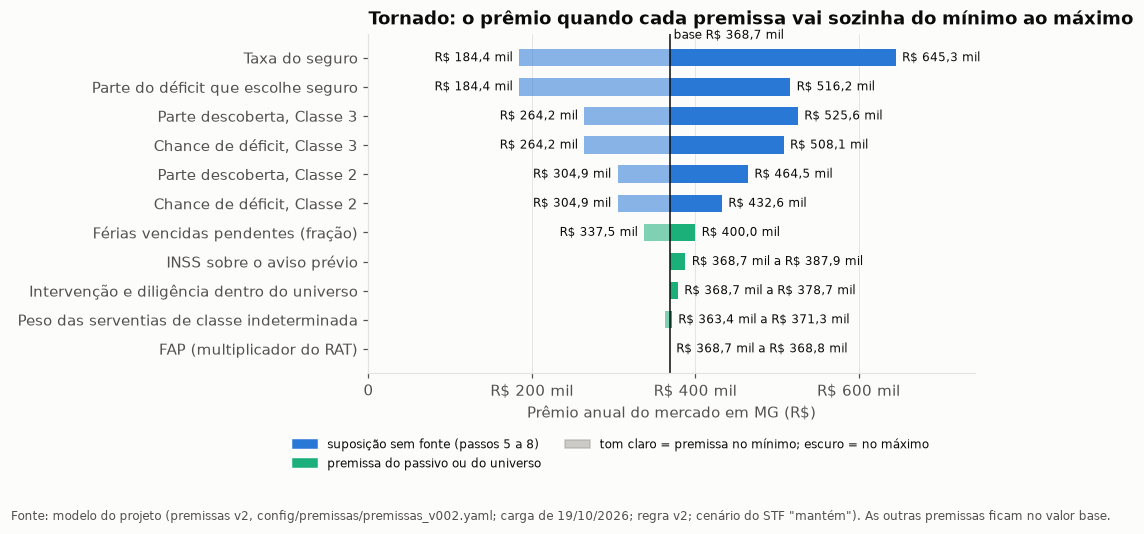

In [2]:
faixas = se.faixas_suposicoes(semente_premissas)
tor_sup = se.tornado(totais, faixas, p, cenarios).assign(grupo="suposição (passos 5 a 8)")
ins = carregar_insumos(con)
tor_rec = se.tornado_recalculo(ins, semente_premissas, peso, limites, cenarios).assign(grupo="passivo e universo")
tor = pd.concat([tor_sup, tor_rec]).sort_values("amplitude", ascending=False).reset_index(drop=True)
t7_tor = pd.DataFrame(t7["tornado"]).set_index("suposicao").rename(index={"prob2": "prob_2", "prob3": "prob_3",
                                                                          "pct2": "pct_2", "pct3": "pct_3"})
tor["no T7 (R$ mil)"] = [f"{g.num(t7_tor.loc[s, 'min_mil'])} – {g.num(t7_tor.loc[s, 'max_mil'])}" if s in t7_tor.index
                         else "—" for s in tor.suposicao]
display(g.tabela(tor[["rotulo", "grupo", "valor_min", "valor_base", "valor_max", "premio_no_min", "premio_no_max",
                      "amplitude", "no T7 (R$ mil)"]],
                 {"premio_no_min": "reais", "premio_no_max": "reais", "amplitude": "reais"}))

fig, ax = plt.subplots(figsize=(9, 4.6))
tt = tor.iloc[::-1]
y = np.arange(len(tt))
b0 = base["mercado_premio_emitido"]
for i, (_, r) in enumerate(tt.iterrows()):
    cor = g.AZUL["medio"] if r.grupo.startswith("suposição") else g.CORES[2]
    ax.barh(i, r.premio_no_min - b0, left=b0, color=cor, alpha=0.55, height=0.6)
    ax.barh(i, r.premio_no_max - b0, left=b0, color=cor, height=0.6)
    lo, hi = sorted([r.premio_no_min, r.premio_no_max])
    if hi - lo < 25e3:   # barra curta: um rótulo só, à direita
        ax.text(hi + 8e3, i, f"{g.reais(lo)} a {g.reais(hi)}".replace("$", r"\$"), ha="left", va="center", fontsize=8)
    else:
        ax.text(lo - 8e3, i, g.reais(lo), ha="right", va="center", fontsize=8)
        ax.text(hi + 8e3, i, g.reais(hi), ha="left", va="center", fontsize=8)
ax.axvline(b0, color=g.TEXTO, linewidth=1)
ax.text(b0, len(tt) - 0.35, f" base {g.reais(b0)}", fontsize=8)
ax.set_yticks(y, tt.rotulo)
ax.set_xlim(0, tor.premio_no_max.max() * 1.15)
ax.set_xticks(np.arange(0, 7e5 + 1, 2e5))
g.eixo_reais(ax, "x")
ax.set_xlabel("Prêmio anual do mercado em MG (R$)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=g.AZUL["medio"], label="suposição sem fonte (passos 5 a 8)"),
                   Patch(color=g.CORES[2], label="premissa do passivo ou do universo"),
                   Patch(color=g.CINZA, alpha=0.55, label="tom claro = premissa no mínimo; escuro = no máximo")],
          loc="upper center", bbox_to_anchor=(0.4, -0.16), ncol=2, fontsize=8)
ax.set_title("Tornado: o prêmio quando cada premissa vai sozinha do mínimo ao máximo")
fig.tight_layout()
g.nota(fig, "Fonte: modelo do projeto (premissas v2, config/premissas/premissas_v002.yaml; carga de 19/10/2026; regra v2; "
            "cenário do STF \"mantém\"). As outras premissas ficam no valor base.")
g.salvar(fig, "08_tornado_premio")
plt.show()

**Como ler.** Cada barra vai do prêmio com a premissa no mínimo (tom claro) até o prêmio com ela no máximo (tom escuro); a linha preta é a base (R$ 368,7 mil). Barra longa: premissa que pesa muito.

**O que encontramos.**
- A **taxa do seguro** é a que mais mexe: sozinha, leva o prêmio de **R$ 184 mil a R$ 645 mil**. Depois vem a **parte do déficit que escolhe seguro** (R$ 184 a 516 mil). As duas são suposições sobre o comportamento do mercado, não sobre os cartórios.
- As quatro suposições de **patrimônio** (chance de déficit e parte descoberta) vêm em seguida; as da **Classe 3** pesam mais que as da Classe 2, porque a Classe 3 tem 73% do passivo das obrigadas (notebook 02).
- As premissas do **passivo e do universo** pesam pouco: a maior, a fração de férias vencidas, move o prêmio em ±8% (R$ 338 a 400 mil); o FAP, quase nada (R$ 109).
- **Bate com o teste T7:** as seis suposições dão exatamente os mesmos valores do teste (coluna "no T7").

**O que significa para o Prov. 227.** A incerteza do prêmio está quase toda no **lado do seguro** (taxa e adesão), não nos dados dos cartórios. Uma cotação real de seguradoras ou uma pesquisa com titulares reduziria a faixa mais do que qualquer melhoria nos dados públicos. No simulador, a taxa e a escolha pelo seguro devem ser os primeiros controles.

**Limitações.** O tornado move uma premissa por vez; não mostra o que acontece quando várias erram juntas (é a seção 2). O mínimo e o máximo de cada suposição também são suposições (D-016).

## 2. Monte Carlo: a faixa realista do prêmio

**A pergunta.** Se todas as suposições forem incertas ao mesmo tempo, onde o prêmio provavelmente cai?

**O método.**
- A faixa oficial de hoje usa os **cantos**: tudo no mínimo (R$ 24,7 mil) e tudo no máximo (R$ 2,79 mi). Para isso acontecer, **todas** as premissas teriam de estar no extremo ao mesmo tempo, o que é muito improvável.
- O **Monte Carlo** sorteia cada suposição muitas vezes (aqui, 200 mil) e calcula o prêmio em cada sorteio. A faixa sai dos **percentis** dos resultados: o **P5** é o valor abaixo do qual ficam 5% dos sorteios; o **P95**, abaixo do qual ficam 95%. Então **90% dos sorteios** caem entre o P5 e o P95.
- **Distribuição triangular:** cada suposição é sorteada entre o mínimo e o máximo, com o valor base como o mais provável (a probabilidade cresce em linha reta do mínimo até o base e cai em linha reta até o máximo). Exemplo: a taxa entre 1% e 3,5%, com 2% como o mais provável: sorteios perto de 2% são frequentes; perto de 1% ou 3,5%, raros.
- **Independentes × patrimônio junto:** na versão escolhida no T7, cada suposição é sorteada sem olhar as outras. Na sensibilidade, as quatro que dependem do patrimônio do titular (chance de déficit e parte descoberta, nas Classes 2 e 3) andam juntas: se uma vai ao alto, as outras também.
- O passivo fica no nível base, como no T7; por isso os cantos desta conta (R$ 27,4 mil e R$ 2,37 mi) são um pouco diferentes dos oficiais, que também mexem no passivo. A conta vetorial (`sensibilidade.premio_vetorial`) é a mesma de `simulador.resumo_por_totais`, conferida em `tests/test_analise_modelos.py`.

**Por que este método.** No T7, o triangular foi escolhido entre o uniforme (que dá a mesma chance a todo valor da faixa, sem usar o base) e o PERT (parecido com o triangular, um pouco mais concentrado no base): ele usa os três valores que o autor aprovou e não inventa uma forma mais detalhada que os dados não sustentam.

,variante,medida,p05,p50,p95,media,canto_min,valor_base,canto_max
0,independentes,deficit,"R$ 27,4 mi","R$ 40,1 mi","R$ 57,2 mi","R$ 40,9 mi","R$ 11,0 mi","R$ 36,9 mi","R$ 96,7 mi"
1,independentes,importancia_segurada,"R$ 11,3 mi","R$ 19,1 mi","R$ 30,3 mi","R$ 19,8 mi","R$ 2,7 mi","R$ 18,4 mi","R$ 67,7 mi"
2,independentes,premio,"R$ 206,1 mil","R$ 402,7 mil","R$ 736,2 mil","R$ 427,7 mil","R$ 27,4 mil","R$ 368,7 mil","R$ 2,4 mi"
3,patrimônio junto,deficit,"R$ 18,0 mi","R$ 40,0 mi","R$ 76,1 mi","R$ 42,7 mi","R$ 11,0 mi","R$ 36,9 mi","R$ 96,7 mi"
4,patrimônio junto,importancia_segurada,"R$ 8,1 mi","R$ 19,0 mi","R$ 38,9 mi","R$ 20,6 mi","R$ 2,7 mi","R$ 18,4 mi","R$ 67,7 mi"
5,patrimônio junto,premio,"R$ 155,2 mil","R$ 398,4 mil","R$ 905,5 mil","R$ 446,8 mil","R$ 27,4 mil","R$ 368,7 mil","R$ 2,4 mi"


,variante,percentil,notebook 08,teste T7
0,independentes,P5,"206,1","206,6"
1,independentes,P50,"402,7","403,8"
2,independentes,P95,"736,2","736,6"
3,patrimônio junto,P5,"155,2","155,4"
4,patrimônio junto,P50,"398,4","399,9"
5,patrimônio junto,P95,"905,5","906,5"


Sorteios abaixo do dobro do canto mínimo (R$ 54,9 mil): 0,00%; acima da metade do canto máximo (R$ 1,2 mi): 0,05%.
Chance de o prêmio ficar abaixo do valor base (R$ 368,7 mil): 41,2%.


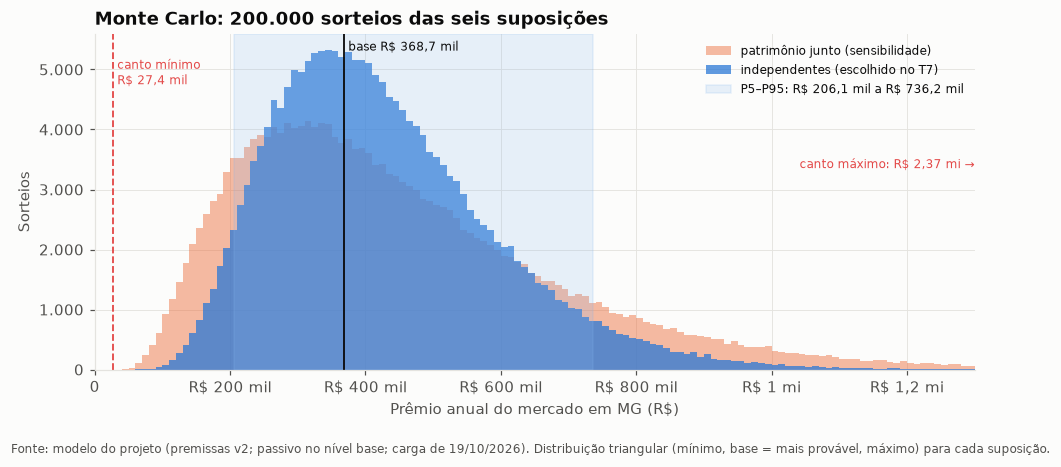

In [3]:
x_ind = se.sortear(faixas, N, SEMENTE)
x_jun = se.sortear(faixas, N, SEMENTE, juntas=se.PATRIMONIO)
mc_ind, mc_jun = se.premio_vetorial(totais, x_ind), se.premio_vetorial(totais, x_jun)
cantos = {n: {k: float(v[0]) for k, v in se.premio_vetorial(totais, {s: np.array([faixas.loc[s, n]])
                                                                       for s in faixas.index}).items()}
          for n in ("min", "base", "max")}
res = {"independentes": se.resumo_sorteios(mc_ind), "patrimônio junto": se.resumo_sorteios(mc_jun)}
analise_monte_carlo = se.tabela_monte_carlo(res, cantos, N, SEMENTE)
mostra = analise_monte_carlo[["variante", "medida", "p05", "p50", "p95", "media", "canto_min", "valor_base", "canto_max"]]
display(g.tabela(mostra, {c: "reais" for c in ["p05", "p50", "p95", "media", "canto_min", "valor_base", "canto_max"]}))

t7_tab = {r["metodo"]: r for r in t7["tabela"]}
comp = pd.DataFrame({
    "notebook 08": [np.quantile(m["premio"], q) / 1e3 for m in (mc_ind, mc_jun) for q in (0.05, 0.5, 0.95)],
    "teste T7": [t7_tab[k][c] for k in ("Monte Carlo triangular", "Monte Carlo triangular, patrimônio correlacionado")
                 for c in ("P5_mil", "P50_mil", "P95_mil")]},
    index=pd.MultiIndex.from_product([["independentes", "patrimônio junto"], ["P5", "P50", "P95"]]))
display(g.tabela(comp.reset_index(names=["variante", "percentil"]), {"notebook 08": "num1", "teste T7": "num1"}))
pm = mc_ind["premio"]
print(f"Sorteios abaixo do dobro do canto mínimo ({g.reais(2 * cantos['min']['premio'])}): {g.pct(np.mean(pm <= 2 * cantos['min']['premio']), 2)}; "
      f"acima da metade do canto máximo ({g.reais(cantos['max']['premio'] / 2)}): {g.pct(np.mean(pm >= cantos['max']['premio'] / 2), 2)}.")
print(f"Chance de o prêmio ficar abaixo do valor base ({g.reais(b0)}): {g.pct(np.mean(pm < b0))}.")

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1.3e6, 131)
ax.hist(mc_jun["premio"], bins=bins, color=g.CORES[1], alpha=0.45, label="patrimônio junto (sensibilidade)")
ax.hist(pm, bins=bins, color=g.AZUL["medio"], alpha=0.75, label="independentes (escolhido no T7)")
q5, q95 = np.quantile(pm, [0.05, 0.95])
ax.axvspan(q5, q95, color=g.AZUL["claro"], alpha=0.18, label=f"P5–P95: {g.reais(q5)} a {g.reais(q95)}".replace("$", r"\$"))   # dois "$" virariam fórmula
ax.axvline(b0, color=g.TEXTO, linewidth=1.2)
ax.text(b0, ax.get_ylim()[1] * 0.95, f" base {g.reais(b0)}", fontsize=8)
ax.axvline(cantos["min"]["premio"], color=g.CORES[7], linestyle="--", linewidth=1.2)
ax.text(cantos["min"]["premio"], ax.get_ylim()[1] * 0.85, f" canto mínimo\n {g.reais(cantos['min']['premio'])}", fontsize=8,
        color=g.CORES[7])
ax.annotate(f"canto máximo: {g.reais(cantos['max']['premio'], 2)} →", xy=(1.3e6, ax.get_ylim()[1] * 0.6), ha="right",
            fontsize=8, color=g.CORES[7])
ax.set_xlim(0, 1.3e6)
g.eixo_reais(ax, "x")
g.eixo_num(ax, "y")
ax.set_xlabel("Prêmio anual do mercado em MG (R$)")
ax.set_ylabel("Sorteios")
ax.legend(loc="upper right", fontsize=8)
ax.set_title(f"Monte Carlo: {g.num(N)} sorteios das seis suposições")
fig.tight_layout()
g.nota(fig, "Fonte: modelo do projeto (premissas v2; passivo no nível base; carga de 19/10/2026). Distribuição triangular "
            "(mínimo, base = mais provável, máximo) para cada suposição.")
g.salvar(fig, "08_monte_carlo_premio")
plt.show()

**Como ler.** O histograma azul conta em quantos sorteios o prêmio caiu em cada faixa de valor; a faixa azul-clara vai do P5 ao P95. O laranja é a sensibilidade com as suposições de patrimônio andando juntas. A linha vermelha tracejada é o canto mínimo; o canto máximo (R$ 2,37 mi) fica fora do gráfico, à direita.

**O que encontramos.**
- **Faixa realista: R$ 206 mil a R$ 736 mil** (P5–P95), com mediana de R$ 403 mil. Bate com o T7 (207, 404 e 737 mil); a pequena diferença é a semente.
- Os **cantos quase nunca acontecem:** nenhum dos 200 mil sorteios ficou abaixo do dobro do canto mínimo (R$ 55 mil), e só 0,05% passaram da metade do canto máximo (R$ 1,2 mi). A faixa de cantos (R$ 27 mil a R$ 2,37 mi) é cerca de **4,4 vezes mais larga** que a P5–P95.
- A distribuição é **assimétrica para cima**: a média (R$ 428 mil) e a mediana (R$ 403 mil) ficam acima da base, e 59% dos sorteios dão mais que a base. Isso acontece porque, em várias suposições, o máximo está mais longe do base que o mínimo (por exemplo, a taxa: 1% – **2%** – 3,5%).
- Se as suposições de patrimônio **andarem juntas**, a faixa alarga para **R$ 155 a 906 mil**.

**O que significa para o Prov. 227.** "O mercado de MG vale entre R$ 200 e 750 mil por ano em prêmio, com R$ 369 mil no cenário base" é uma frase mais honesta do que "entre R$ 25 mil e R$ 2,8 milhões". A proposta (já no `plano_projeto.md`) é o painel mostrar a faixa P5–P95 **ao lado** dos cantos; o valor base não muda.

**Limitações.**
- A faixa P5–P95 é tão boa quanto as faixas das suposições, que não têm fonte. Ela mede a incerteza **dentro** dessas faixas, não o risco de as faixas estarem erradas.
- Supor as seis independentes é uma escolha; a variante "patrimônio junto" mostra o efeito de relaxá-la. A taxa e a adesão ao seguro também podem andar juntas na prática (taxa alta, menos adesão), o que estreitaria a faixa; isso não foi modelado.
- O passivo fica no nível base. Pelo tornado, as premissas do passivo movem o prêmio em menos de ±10%, o que alargaria pouco a faixa.

### Entrega: desenho da `gold.analise_tornado` e da `gold.analise_monte_carlo`

As tabelas que o pipeline vai gravar na Etapa 2 (funções `tabela_tornado` e `tabela_monte_carlo` em `src/analise/sensibilidade.py`, com teste):
- **`analise_tornado`:** uma linha por premissa, com o mínimo, o base e o máximo da premissa, o prêmio em cada ponta, a amplitude e a ordem. Serve para o tornado do simulador.
- **`analise_monte_carlo`:** uma linha por variante (independentes; patrimônio junto) e medida (déficit, IS, prêmio), com a média, os percentis P5, P25, P50, P75 e P95, os cantos e o valor base ao lado, o número de sorteios e a semente. Serve para mostrar a faixa P5–P95 ao lado dos cantos no painel.

In [4]:
analise_tornado = se.tabela_tornado(tor)
print(f"gold.analise_tornado (desenho): {len(analise_tornado)} linhas; colunas: {', '.join(analise_tornado.columns)}.")
print(f"gold.analise_monte_carlo (desenho): {len(analise_monte_carlo)} linhas (2 variantes × 3 medidas); colunas: "
      f"{', '.join(analise_monte_carlo.columns)}.")

gold.analise_tornado (desenho): 11 linhas; colunas: suposicao, rotulo, grupo, valor_min, valor_base, valor_max, premio_no_min, premio_base, premio_no_max, amplitude, ordem.
gold.analise_monte_carlo (desenho): 6 linhas (2 variantes × 3 medidas); colunas: variante, medida, media, p05, p25, p50, p75, p95, canto_min, valor_base, canto_max, n_sorteios, semente, distribuicao.


## 3. Sensibilidade do passivo: salário ausente (T5) e reserva salarial (T6)

**A pergunta.** O passivo (números 4 e 5 do painel) muda muito se tratarmos de outro jeito dois pontos fracos dos dados da RAIS?

**O método.**
- **T5 — salário de dezembro ausente.** A base (D-015) deixa fora os vínculos sem salário de dezembro: o passivo médio por vínculo do município sai só dos outros, e o CLT do CNJ continua o mesmo. Na sensibilidade, esses vínculos entram com um salário estimado: se têm remuneração no ano, **remuneração média × razão dezembro ÷ média** (a razão mediana dos vínculos conhecidos; o vencedor do T5); se não têm nenhuma, a mediana de dezembro da região imediata.
- **T6 — municípios com poucos vínculos.** A base (D-008, D-022) usa a média do próprio município só se ele tiver 20 vínculos ou mais; senão, usa a da região imediata. Na sensibilidade, o município com 1 a 19 vínculos usa uma **mistura**: λ × (média dele) + (1 − λ) × (média da região). O peso λ = τ² ÷ (τ² + σ²/n) cresce com o número de vínculos n: τ² é o quanto os municípios grandes diferem entre si, e σ² é o quanto os vínculos diferem dentro de um município. Exemplo: se λ = 0,2, um município com média de R$ 30 mil numa região com R$ 20 mil fica com 0,2 × 30 + 0,8 × 20 = R$ 22 mil. Esse é o **encolhimento** (ou Bayes empírico): a média de poucos vínculos é "puxada" para a da região, tanto mais quanto menos vínculos houver.
- Os dois recalculam o modelo inteiro (rateio, universo, déficit, prêmio) com as funções do pipeline. Para comparar, a última linha traz uma sensibilidade que o pipeline já calcula (`gold.sensibilidade_premissas`): a reserva no estado inteiro, sem a região.

,variação,passivo_medio_vinculo_MG,passivo_todas,passivo_universo,valor_descoberto,premio,Δ passivo_medio_vinculo_MG,Δ passivo_todas,Δ passivo_universo,Δ premio
0,Base (D-015 e D-022),"R$ 23.988,47","R$ 311,9 mi","R$ 238,1 mi","R$ 36,9 mi","R$ 368,7 mil","0,0%","0,0%","0,0%","0,0%"
1,T5: incluir os vínculos sem salário de dezembr...,"R$ 24.233,49","R$ 313,8 mi","R$ 239,2 mi","R$ 37,0 mi","R$ 370,1 mil","1,0%","0,6%","0,5%","0,4%"
2,T6: reserva por encolhimento (município pequen...,—,"R$ 306,9 mi","R$ 235,3 mi","R$ 36,3 mi","R$ 362,6 mil",—,"-1,6%","-1,2%","-1,7%"
3,Para comparar (gold.sensibilidade_premissas): ...,—,"R$ 330,1 mi","R$ 246,6 mi","R$ 38,9 mi","R$ 388,8 mil",—,"5,9%","3,6%","5,4%"


T5: 887 vínculos estimados (733 por mediana_regiao_imediata, 154 por remuneracao_media_x_razao); razão dezembro ÷ média = 1,000; tempo de casa mediano deles: 85 meses.
T6: 610 municípios com 1 a 19 vínculos passam a misturar a própria média com a da região; peso λ da própria média: mediana 0,14 (de 0,05 a 0,51).


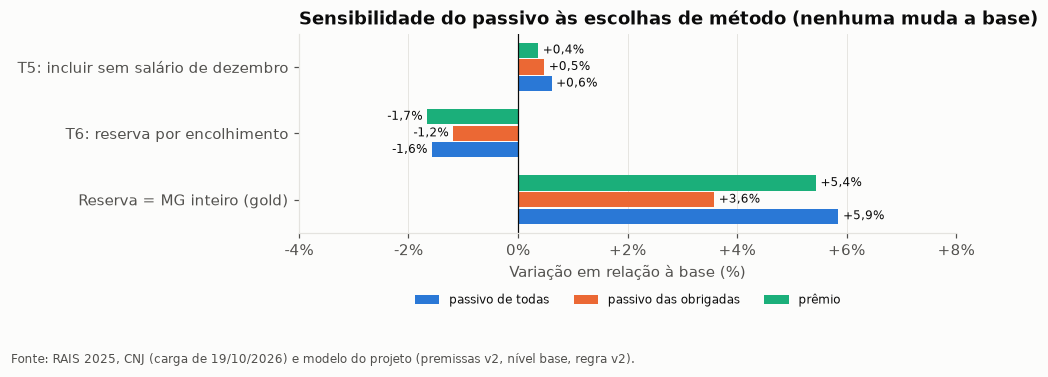

In [5]:
def linha(rotulo, serv, p_, vinc=None):
    r = resumo_mercado(serv, p_, cenarios, "mantem")
    return {"variação": rotulo, "passivo_medio_vinculo_MG": passivo_vinculos(vinc, p_).mean() if vinc is not None else np.nan,
            "passivo_todas": r["passivo_todas"], "passivo_universo": r["passivo_universo"],
            "valor_descoberto": r["valor_descoberto"], "premio": r["mercado_premio_emitido"]}

serv0 = calcular_serventias(ins, p, limites, limites_faixa=limites)[0]
vinc0 = se.vinculos_base(ins, p)
linhas = [linha("Base (D-015 e D-022)", serv0, p, vinc0)]

rais5, estimados = se.rais_com_salario_estimado(ins.rais, ins.regioes)
ins5 = Insumos(rais=rais5, serventias=ins.serventias, fator_inpc=ins.fator_inpc, mes_inpc=ins.mes_inpc, regioes=ins.regioes)
linhas.append(linha("T5: incluir os vínculos sem salário de dezembro, com salário estimado",
                    calcular_serventias(ins5, p, limites, limites_faixa=limites)[0], p, se.vinculos_base(ins5, p)))
municipios = ins.serventias.cod_ibge.dropna().astype(int).unique().tolist()
limiar = int(p["limiar_vinculos_distribuicao_municipal"])
medio6 = se.medio_com_encolhimento(vinc0, municipios, p, limiar, ins.regioes)
linhas.append(linha("T6: reserva por encolhimento (município pequeno mistura a própria média com a da região)",
                    se.calcular_com_medio(ins, p, limites, medio6), p))
sens_gold = con.execute("SELECT * FROM gold.sensibilidade_premissas WHERE chave = 'sem_regiao'").df().iloc[0]
linhas.append({"variação": "Para comparar (gold.sensibilidade_premissas): reserva = MG inteiro, sem a região",
               "passivo_medio_vinculo_MG": np.nan, "passivo_todas": sens_gold.passivo_todas,
               "passivo_universo": sens_gold.passivo_universo, "valor_descoberto": sens_gold.valor_descoberto,
               "premio": sens_gold.mercado_premio_emitido})
sens = pd.DataFrame(linhas)
for c in ["passivo_medio_vinculo_MG", "passivo_todas", "passivo_universo", "premio"]:
    sens[f"Δ {c}"] = sens[c] / sens[c].iloc[0] - 1
display(g.tabela(sens, {"passivo_medio_vinculo_MG": "reais_cheio", "passivo_todas": "reais", "passivo_universo": "reais",
                        "valor_descoberto": "reais", "premio": "reais", **{f"Δ {c}": "pct" for c in
                        ["passivo_medio_vinculo_MG", "passivo_todas", "passivo_universo", "premio"]}}))
print(f"T5: {g.num(len(estimados))} vínculos estimados ({', '.join(f'{g.num(n)} por {m}' for m, n in estimados.metodo.value_counts().items())}); "
      f"razão dezembro ÷ média = {g.num(estimados.razao.iloc[0], 3)}; tempo de casa mediano deles: "
      f"{g.num(ins.rais.loc[estimados.index, 'tempo_emprego_meses'].median())} meses.")
pq = medio6[medio6.origem_distribuicao == "encolhimento"]
print(f"T6: {g.num(len(pq))} municípios com 1 a {limiar - 1} vínculos passam a misturar a própria média com a da região; "
      f"peso λ da própria média: mediana {g.num(pq['lambda'].median(), 2)} (de {g.num(pq['lambda'].min(), 2)} a "
      f"{g.num(pq['lambda'].max(), 2)}).")

fig, ax = plt.subplots(figsize=(9, 3.2))
s = sens.iloc[1:].iloc[::-1]
rot = ["Reserva = MG inteiro (gold)", "T6: reserva por encolhimento", "T5: incluir sem salário de dezembro"]
x = np.arange(len(s))
for j, (c, nome, cor) in enumerate([("Δ passivo_todas", "passivo de todas", g.AZUL["medio"]),
                                    ("Δ passivo_universo", "passivo das obrigadas", g.CORES[1]),
                                    ("Δ premio", "prêmio", g.CORES[2])]):
    barras = ax.barh(x + (j - 1) * 0.25, 100 * s[c], height=0.23, color=cor, label=nome)
    ax.bar_label(barras, [f"{100 * v:+.1f}%".replace(".", ",") for v in s[c]], padding=3, fontsize=8)
ax.axvline(0, color=g.TEXTO, linewidth=0.8)
ax.set_yticks(x, rot)
ax.set_xlim(-4, 8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0f}%" if v else "0%"))
ax.set_xlabel("Variação em relação à base (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, fontsize=8)
ax.set_title("Sensibilidade do passivo às escolhas de método (nenhuma muda a base)")
fig.tight_layout()
g.nota(fig, "Fonte: RAIS 2025, CNJ (carga de 19/10/2026) e modelo do projeto (premissas v2, nível base, regra v2).")
g.salvar(fig, "08_sensibilidade_passivo")
plt.show()

**Como ler.** Cada grupo de barras é uma forma alternativa de calcular o passivo; o tamanho da barra é a variação em relação à base, em %.

**O que encontramos.**
- **T5 (salário ausente):** incluir os **887** vínculos sem salário de dezembro sobe o passivo médio por vínculo de MG em **+1,0%** (de R$ 23.988 para R$ 24.233), como no teste. No passivo total, o efeito é ainda menor (**+0,6%**; obrigadas +0,5%; prêmio +0,4%), porque o número de empregados vem do CNJ e não muda: só o passivo médio dos municípios onde esses vínculos estão. Eles pesam porque têm mais tempo de casa (mediana de 85 meses, contra 31 dos demais).
- **T6 (encolhimento):** os **610** municípios com 1 a 19 vínculos passam a dar um peso pequeno à própria média (λ mediano de 0,14). O passivo cai **−1,6%** (obrigadas −1,2%; prêmio −1,7%).
- Para comparar, trocar a região pelo **estado inteiro** como reserva (como era antes da D-022) sobe o passivo em **+5,9%**. Ou seja, a escolha da reserva pesa mais do que o detalhe de como misturar município e região.

**O que significa para o Prov. 227.** O passivo (números 4 e 5) é **robusto** a esses dois pontos fracos dos dados: as duas sensibilidades ficam dentro de ±2%, muito menos que a incerteza das suposições do déficit (seções 1 e 2). As decisões D-015 e D-022 podem ficar na base, com essas linhas na tabela de sensibilidade (proposta já no `plano_projeto.md`).

**Limitações.** O salário estimado dos 733 vínculos sem nenhuma remuneração no ano é a mediana da região: se eles forem afastados de longa duração, talvez nem devessem entrar no passivo. O λ usa as variâncias dos 135 municípios grandes; os pequenos podem ser mais parecidos com a própria região do que isso supõe (a mesma ressalva do T6).

## 4. Concentração: quanto está nos maiores?

**A pergunta.** O mercado é feito de muitos contratos parecidos ou de poucos contratos grandes?

**O método.**
- **Curva de concentração (Lorenz):** ordena as serventias da menor para a maior e acumula. Um ponto (60%, 10%) quer dizer que as 60% menores somam 10% do total. Se todas fossem iguais, a curva seria a diagonal.
- **Índice de Gini:** o dobro da área entre a diagonal e a curva. Vai de 0 (todas iguais) a perto de 1 (tudo numa só). Exemplo: quatro serventias com passivo 0, 0, 0 e 100 têm Gini 0,75 (o máximo com quatro); com 25 cada, Gini 0.
- **Os 10% maiores:** que parte do total eles têm (`config/analise.yaml`, `topo_concentracao`).

Para as obrigadas, o passivo de cada serventia é multiplicado pelo peso dela no universo (1 para as de classe conhecida; 0,68 para as de classe indeterminada), como no painel.

,medida,serventias,gini,10% maiores têm,1% maiores têm,50% menores têm
0,Receita de referência 2025 (todas),2.447,"0,74","62,3%","20,0%","5,6%"
1,Passivo (todas),2.525,"0,71","60,5%","20,3%","7,6%"
2,Passivo das obrigadas (passivo × peso),1.130,"0,63","53,5%","15,1%","12,2%"
3,Déficit esperado (obrigadas),1.130,"0,52","42,9%","11,7%","17,7%"


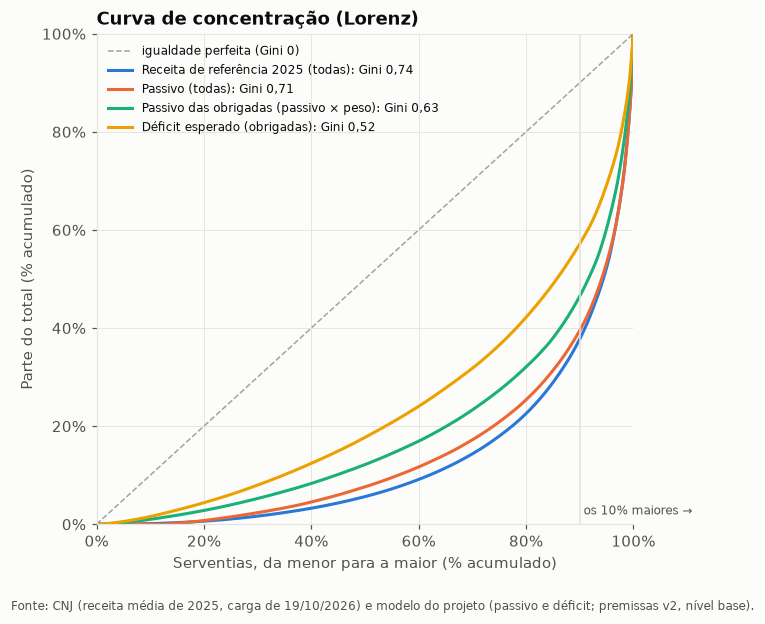

In [6]:
topo = cfg["sensibilidade"]["topo_concentracao"]
obr = sv[sv.peso_universo > 0]
series = {"Receita de referência 2025 (todas)": sv.receita_ref, "Passivo (todas)": sv.passivo,
          "Passivo das obrigadas (passivo × peso)": obr.passivo * obr.peso_universo,
          "Déficit esperado (obrigadas)": obr.valor_descoberto}
conc = pd.DataFrame([{"medida": n, "serventias": int(s.notna().sum()), "gini": est.gini(s),
                      f"{round(100 * topo)}% maiores têm": est.participacao_topo(s, topo),
                      "1% maiores têm": est.participacao_topo(s, 0.01),
                      "50% menores têm": 1 - est.participacao_topo(s, 0.5)} for n, s in series.items()])
display(g.tabela(conc, {"serventias": "int", "gini": "num2", f"{round(100 * topo)}% maiores têm": "pct",
                        "1% maiores têm": "pct", "50% menores têm": "pct"}))

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.plot([0, 1], [0, 1], color=g.CINZA, linestyle="--", linewidth=1, label="igualdade perfeita (Gini 0)")
for (n, s), cor in zip(series.items(), g.CORES):
    c = est.curva_lorenz(s)
    ax.plot(c.fracao_unidades, c.fracao_valor, color=cor, linewidth=2, label=f"{n}: Gini {g.num(est.gini(s), 2)}")
ax.axvline(1 - topo, color=g.GRADE, linewidth=1)
ax.text(1 - topo, 0.02, f" os {round(100 * topo)}% maiores →", fontsize=8, color=g.TEXTO_2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: g.pct(v, 0)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: g.pct(v, 0)))
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Serventias, da menor para a maior (% acumulado)")
ax.set_ylabel("Parte do total (% acumulado)")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Curva de concentração (Lorenz)")
fig.tight_layout()
g.nota(fig, "Fonte: CNJ (receita média de 2025, carga de 19/10/2026) e modelo do projeto (passivo e déficit; premissas v2, "
            "nível base).")
g.salvar(fig, "08_concentracao_lorenz")
plt.show()

**Como ler.** Quanto mais a curva se afasta da diagonal, mais concentrado. A linha vertical marca onde começam os 10% maiores: a altura da curva ali é o que os 90% menores somam.

**O que encontramos.**
- **Receita** (Gini 0,74) e **passivo** de todas as serventias (Gini 0,71) são muito concentrados: os 10% maiores têm **62%** da receita e **61%** do passivo; a metade menor, só 6% e 8%.
- Entre as **obrigadas**, a concentração é menor (Gini 0,63; os 10% maiores têm **54%** do passivo), porque a Classe 1, que tem as menores, já está fora.
- O **déficit esperado** é o menos concentrado (Gini 0,52; 10% maiores com **43%**): o modelo supõe chance de déficit e parte descoberta **maiores na Classe 2** (50% e 50%) do que na Classe 3 (30% e 40%), o que puxa o déficit para as médias.

**O que significa para o Prov. 227.** Para uma seguradora, o mercado é de **poucos contratos grandes e muitos pequenos**: os ≈ 113 maiores contratos (10% das obrigadas) somariam ≈ 43% da importância segurada (a IS é proporcional ao déficit esperado). Isso favorece uma estratégia de venda dirigida aos maiores cartórios, mas também concentra o risco em poucos tomadores.

**Limitações.** O déficit por serventia é um **valor esperado** (probabilidade × parte descoberta × passivo), não o déficit real de cada uma: no mundo real, cada serventia tem ou não tem déficit, e a concentração do déficit real seria maior.

## 5. Receita líquida do Prov. 213, como sensibilidade

**A pergunta.** A norma manda classificar o cartório pela receita **depois** de tirar os repasses obrigatórios. Quantas providas deixariam de passar de R$ 300 mil, e quanto isso mudaria o mercado?

**O texto da norma** (art. 2º, incisos XXIV a XXVI, do Prov. 213, com a redação do Prov. 243; lido do bronze, `data/bronze/normas/2026-10-17/prov_213_2026_pagina.txt`):

In [7]:
norma = (raiz / "data/bronze/normas/2026-10-17/prov_213_2026_pagina.txt").read_text(encoding="utf-8").splitlines()
for prefixo in ("XXIV - ", "XXV - ", "XXVI - "):
    print(next(l for l in norma if l.startswith(prefixo)), end="\n\n")

XXIV - receita bruta semestral da serventia: o somatório dos valores percebidos a título de emolumentos, e outras receitas, no semestre em razão da prestação do serviço delegado, inclusive o ressarcimento por atos gratuitos e a complementação de renda mínima, deduzidos, exclusivamente, os valores arrecadados por conta de terceiros e os repasses legais obrigatórios; não se deduzem, para esse fim, as despesas de custeio, de pessoal ou de investimento da serventia, nem os tributos devidos pelo delegatário; (incluído pelo Provimento CN n. 243, de 21.7.2026)

XXV - valores arrecadados por conta de terceiros: valores acrescidos aos emolumentos para ressarcimento de despesas (envio de documentos, entrega de intimação, tarifas bancárias, publicação de edital etc.) ou para repasse a outras serventias; (incluído pelo Provimento CN n. 243, de 21.7.2026)

XXVI - repasses legais obrigatórios: as parcelas que, por força de lei estadual ou distrital, se destinem ao Estado ou ao Distrito Federal e Ter

**O método.**
- O painel classifica pela **arrecadação** da API do Justiça Aberta (D-002: a classificação é aproximada, porque a arrecadação pública não é a receita bruta do inciso XXIV).
- O **BI do CNJ** traz, por serventia e semestre, a arrecadação e o **repasse** (o que vai para o Estado, o Tribunal, os fundos de atos gratuitos etc., que é o inciso XXVI). A receita mais próxima da norma é **arrecadação − repasse**. Ela é calculada com a mesma regra do painel (média dos semestres de 2025 com valor > 0). Num semestre em que o repasse declarado passa da arrecadação (provável erro de declaração), a receita líquida fica em zero.
- **Contagem:** providas acima de R$ 300 mil pela arrecadação (API e BI) e pela receita líquida (BI).
- **Efeito no mercado:** refazemos o modelo inteiro com a receita da API multiplicada por (1 − fração de repasse da mesma serventia no BI). Assim, a única diferença para a base é o desconto do repasse. Serventia ausente do BI fica sem desconto.
- **Faixa de déficit da base (D-019):** a receita líquida muda **quem entra** no universo, mas a chance de déficit e a parte descoberta de cada serventia continuam as da classe dela na base. É a mesma regra da sensibilidade da regra v1 (D-019): uma leitura alternativa da norma muda o universo, não o risco de quem fica. Exemplo: uma serventia de Classe 3 pela arrecadação que vira Classe 2 pela receita líquida continua obrigada, com a faixa de déficit da Classe 3. A versão com a faixa pela própria receita líquida aparece só como nota, na terceira linha da tabela.

,medida,providas acima de R$ 300 mil,providas sem o dado
0,API do Justiça Aberta: arrecadação (base do pa...,1103,27
1,BI do CNJ: arrecadação,1095,30
2,BI do CNJ: arrecadação − repasse,873,30


Providas: 1.654. Fração de repasse no BI em 2025 (providas): mediana 35,2%, Q1 28,8%, Q3 38,7%; repasse zero: 36; semestres com repasse maior que a arrecadação (zerados): 8.
Providas que passam de R$ 300 mil pela arrecadação do BI e ficam abaixo pela receita líquida: 222; receita líquida mediana delas: R$ 245,7 mil.


,leitura,providas_acima,n_universo,passivo_universo,n_deficit,valor_descoberto,mercado_importancia_segurada,mercado_premio_emitido
0,Base: arrecadação da API,1.103,"1.121,3","R$ 238,1 mi","486,0","R$ 36,9 mi","R$ 18,4 mi","R$ 368,7 mil"
1,"Sensibilidade: receita líquida, faixa de défic...",879,"893,6","R$ 225,6 mi","373,7","R$ 33,7 mi","R$ 16,9 mi","R$ 337,4 mil"
2,"Nota: receita líquida, faixa de déficit pela p...",879,"893,6","R$ 225,6 mi","404,7","R$ 38,1 mi","R$ 19,0 mi","R$ 380,8 mil"
3,Diferença da sensibilidade (%),"-20,3%","-20,3%","-5,3%","-23,1%","-8,5%","-8,5%","-8,5%"
4,Diferença da nota (%),"-20,3%","-20,3%","-5,3%","-16,7%","3,3%","3,3%","3,3%"


Peso das serventias de classe indeterminada: base 0,678; com a receita líquida 0,542 (recalculado como no pipeline, gold.sensibilidade_premissas).


,classe_base,classe_liquida,providas,deficit_base,deficit_faixa_base,deficit_faixa_liquida
0,1,1,524,R$ 0,R$ 0,R$ 0
1,2,1,224,"R$ 3,0 mi",R$ 0,R$ 0
2,2,2,525,"R$ 12,4 mi","R$ 12,4 mi","R$ 12,4 mi"
3,3,2,155,"R$ 4,0 mi","R$ 4,0 mi","R$ 8,3 mi"
4,3,3,199,"R$ 16,9 mi","R$ 16,9 mi","R$ 16,9 mi"
5,indeterminada,indeterminada,27,"R$ 535,6 mil","R$ 427,9 mil","R$ 427,9 mil"


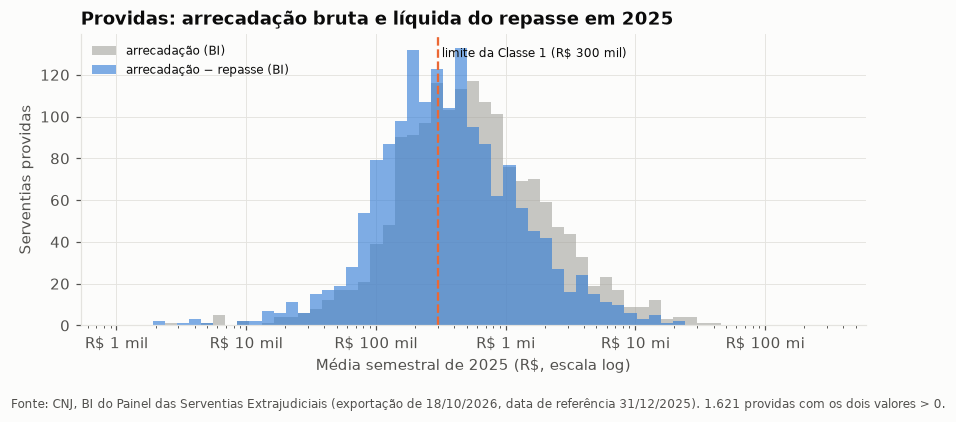

In [8]:
bi = dados.arrecadacao_bi(con)
bi = bi[bi.cns.isin(sv.cns)]
ref_bi = se.receita_ref_bi(bi, 2025)
x = sv.merge(ref_bi, on="cns", how="left")
prov = x[x.situacao == "provida"]
L = limites["classe_1_max"]
cont = pd.DataFrame([
    ("API do Justiça Aberta: arrecadação (base do painel)", prov.receita_ref),
    ("BI do CNJ: arrecadação", prov.arrecadacao_bi),
    ("BI do CNJ: arrecadação − repasse", prov.liquida_bi)], columns=["medida", "s"])
cont["providas acima de R$ 300 mil"] = [int((s > L).sum()) for s in cont.s]
cont["providas sem o dado"] = [int(s.isna().sum()) for s in cont.s]
display(cont.drop(columns="s"))
print(f"Providas: {g.num(len(prov))}. Fração de repasse no BI em 2025 (providas): mediana {g.pct(prov.fracao_repasse.median())}, "
      f"Q1 {g.pct(prov.fracao_repasse.quantile(.25))}, Q3 {g.pct(prov.fracao_repasse.quantile(.75))}; "
      f"repasse zero: {g.num((prov.repasse_bi == 0).sum())}; semestres com repasse maior que a arrecadação (zerados): "
      f"{g.num(prov.semestres_repasse_maior.sum())}.")
caem = prov[(prov.arrecadacao_bi > L) & (prov.liquida_bi <= L)]
print(f"Providas que passam de R$ 300 mil pela arrecadação do BI e ficam abaixo pela receita líquida: {g.num(len(caem))}; "
      f"receita líquida mediana delas: {g.reais(caem.liquida_bi.median())}.")

ins_liq = se.insumos_receita_liquida(ins, ref_bi)
peso_liq = peso_indeterminada(ins_liq.serventias, limites)
p_liq = premissas_nivel(semente_premissas, "base", peso_liq)
serv_liq_faixa_liq = calcular_serventias(ins_liq, p_liq, limites, limites_faixa=limites)[0]
serv_liq = se.com_faixa_da_base(serv_liq_faixa_liq, serv0, p_liq)   # faixa de déficit da base (D-019)

def linha_efeito(rotulo, s, p_):
    acima = int(((s.situacao_juridica == "PROVIDO") & s.classe.isin(["2", "3"])).sum())
    return {"leitura": rotulo, "providas_acima": acima, **resumo_mercado(s, p_, cenarios, "mantem")}

colunas = ["leitura", "providas_acima", "n_universo", "passivo_universo", "n_deficit", "valor_descoberto",
           "mercado_importancia_segurada", "mercado_premio_emitido"]
efeito = pd.DataFrame([linha_efeito("Base: arrecadação da API", serv0, p),
                       linha_efeito("Sensibilidade: receita líquida, faixa de déficit da base (D-019)", serv_liq, p_liq),
                       linha_efeito("Nota: receita líquida, faixa de déficit pela própria receita líquida",
                                    serv_liq_faixa_liq, p_liq)])[colunas]
dif = efeito.iloc[1:, 1:].astype(float).div(efeito.iloc[0, 1:].astype(float)) - 1
dif.insert(0, "leitura", ["Diferença da sensibilidade (%)", "Diferença da nota (%)"])
fmt = {c: "reais" for c in ["passivo_universo", "valor_descoberto", "mercado_importancia_segurada", "mercado_premio_emitido"]}
display(pd.concat([g.tabela(efeito, fmt | {"providas_acima": "int", "n_universo": "num1", "n_deficit": "num1"}),
                   g.tabela(dif, {c: "pct" for c in dif.columns[1:]})], ignore_index=True))
print(f"Peso das serventias de classe indeterminada: base {g.num(peso, 3)}; com a receita líquida {g.num(peso_liq, 3)} "
      f"(recalculado como no pipeline, gold.sensibilidade_premissas).")

# providas que mudam de classe e o déficit esperado delas: com a faixa da base e, na nota, com a faixa pela líquida
mig = serv0[["cns", "situacao_juridica", "classe", "valor_descoberto"]].merge(
    serv_liq[["cns", "classe", "valor_descoberto"]], on="cns", suffixes=("_base", "_liquida")).merge(
    serv_liq_faixa_liq[["cns", "valor_descoberto"]].rename(columns={"valor_descoberto": "valor_descoberto_nota"}), on="cns")
mig = mig[mig.situacao_juridica == "PROVIDO"].groupby(["classe_base", "classe_liquida"]).agg(
    providas=("cns", "size"), deficit_base=("valor_descoberto_base", "sum"),
    deficit_faixa_base=("valor_descoberto_liquida", "sum"), deficit_faixa_liquida=("valor_descoberto_nota", "sum")
).reset_index()
display(g.tabela(mig, {"providas": "int", "deficit_base": "reais", "deficit_faixa_base": "reais",
                       "deficit_faixa_liquida": "reais"}))

fig, ax = plt.subplots(figsize=(8, 3.6))
ok = prov[(prov.arrecadacao_bi > 0) & (prov.liquida_bi > 0)]
bins = np.logspace(3, 8.5, 60)
ax.hist(ok.arrecadacao_bi, bins=bins, color=g.CINZA, alpha=0.6, label="arrecadação (BI)")
ax.hist(ok.liquida_bi, bins=bins, color=g.AZUL["medio"], alpha=0.6, label="arrecadação − repasse (BI)")
ax.axvline(L, color=g.CORES[1], linestyle="--", linewidth=1.5)
ax.text(L, ax.get_ylim()[1] * 0.92, " limite da Classe 1 (R$ 300 mil)", fontsize=8)
ax.set_xscale("log")
g.eixo_reais(ax, "x")
ax.set_xlabel("Média semestral de 2025 (R$, escala log)")
ax.set_ylabel("Serventias providas")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Providas: arrecadação bruta e líquida do repasse em 2025")
fig.tight_layout()
g.nota(fig, "Fonte: CNJ, BI do Painel das Serventias Extrajudiciais (exportação de 18/10/2026, data de referência 31/12/2025). "
            f"{g.num(len(ok))} providas com os dois valores > 0.")
g.salvar(fig, "08_receita_liquida_providas")
plt.show()

**Como ler.** No histograma, cinza é a arrecadação; azul, a arrecadação menos o repasse. Quando se tira o repasse, a distribuição anda para a esquerda e uma parte das providas atravessa a linha dos R$ 300 mil.

**O que encontramos.**
- O **repasse** é, na mediana, **35%** da arrecadação das providas (metade delas entre 29% e 39%).
- Pela arrecadação, **1.103** providas passam de R$ 300 mil (API; 1.095 pelo BI). Pela **receita líquida do repasse**, só **873** (BI): **222** providas deixariam a Classe 2 para a 1 e sairiam da obrigação, com receita líquida mediana de R$ 246 mil.
- No modelo inteiro, com a faixa de déficit da base, o **universo de obrigadas cai 20%** (1.121 → 894), o passivo das obrigadas cai 5% (as que saem são pequenas) e o **déficit, a IS e o prêmio caem 8,5%** (prêmio de R$ 368,7 mil para **R$ 337,4 mil**; déficit de R$ 36,9 mi para R$ 33,7 mi). A queda vem das 224 providas que saem da Classe 2 (−R$ 3,0 mi de déficit) e de as 27 indeterminadas pesarem menos no universo (o peso cai de 0,68 para 0,54, porque mais serventias de classe conhecida ficam na Classe 1; −R$ 0,1 mi).
- **Nota (faixa pela receita líquida):** se a faixa de déficit seguisse a classe pela receita líquida, o prêmio **subiria 3,3%** (R$ 380,8 mil), porque as **155 providas que descem da Classe 3 para a 2** herdariam a chance de déficit e a parte descoberta maiores da Classe 2, e o déficit delas dobraria (+R$ 4,3 mi). Nada mudou nessas serventias além do rótulo. Universo menor com prêmio maior é o que o teste de monotonicidade da D-019 quer impedir, por isso essa versão fica só como nota.
- Dados do BI: 36 providas com repasse zero (provável falta de informação; ficam sem desconto, o que é conservador) e 8 semestres com repasse maior que a arrecadação (zerados).

**O que significa para o Prov. 227.** Esta é a maior sensibilidade de **quem** é obrigado: ler a norma ao pé da letra tira um quinto das serventias do universo. O mercado em reais cai menos (−8,5%), porque as que saem são pequenas: perto do limite de R$ 300 mil, com pouco passivo. Se o CNJ passar a publicar a receita do inciso XXIV, o universo deve ser recalculado.

**Limitações.**
- O repasse do BI é uma aproximação dos "repasses legais obrigatórios" do inciso XXVI; os "valores arrecadados por conta de terceiros" (inciso XXV: correio, edital, tarifas) **não estão** em nenhuma fonte pública e não foram descontados. A receita líquida real seria um pouco **menor**, e mais serventias sairiam.
- O resultado depende das faixas de déficit por classe (D-011), que são suposições ligadas à classe da norma, não calibradas por renda: por isso a faixa fica a da base, e a versão pela receita líquida é só nota. **Sem mudar a base:** o painel continua com a arrecadação (D-002).

## 6. Resumo dos achados

1. **A taxa e a adesão ao seguro dominam a incerteza.** Sozinha, a taxa leva o prêmio de R$ 184 a 645 mil; a parte que escolhe seguro, de R$ 184 a 516 mil. As premissas do passivo movem o prêmio em menos de ±10%.
2. **Faixa realista do prêmio: R$ 206 a 736 mil** (P5–P95 do Monte Carlo), contra R$ 27 mil a R$ 2,37 mi dos cantos. Os cantos quase nunca acontecem (0,05% dos sorteios passam da metade do máximo). Com o patrimônio junto: R$ 155 a 906 mil.
3. **O passivo é robusto:** incluir os vínculos sem salário de dezembro (T5) muda +0,6%; a reserva por encolhimento (T6), −1,6%.
4. **Mercado concentrado:** os 10% maiores têm 54% do passivo das obrigadas (Gini 0,63); o déficit esperado é menos concentrado (43%; Gini 0,52).
5. **A receita líquida do Prov. 213 tira 20% do universo** (222 providas abaixo de R$ 300 mil sem o repasse) e **8,5% do prêmio** (R$ 337,4 mil), com a faixa de déficit da base (D-019). Com a faixa pela receita líquida (só nota), o prêmio subiria 3,3%, por mudança de rótulo em 155 serventias.

**Entregas:** desenho da `gold.analise_tornado` e da `gold.analise_monte_carlo` (`src/analise/sensibilidade.py`, com teste em `tests/test_analise_modelos.py`).

**Para o cálculo do painel:** nada aqui muda os 10 números. Propostas para o autor: mostrar a faixa P5–P95 ao lado dos cantos; T5 e T6 como linhas de sensibilidade; a receita líquida como sensibilidade do universo, com a ressalva do inciso XXV.

> **Atualização (2026-10-28, notebook 10, melhorias M7 e M8).** (M7) O prêmio por cenário do STF: mantida a regra, R$ 368,7 mil (P5–P95 de R$ 206 a 736 mil); no cenário parcial, metade; com os arts. 8º a 17 suspensos, zero. O risco jurídico não cabe na faixa do Monte Carlo: o painel deve mostrar o prêmio condicionado ao cenário. (M8) A SES da SUSEP **não** publica a importância segurada (conferido em 28/10 no índice do arquivo completo e no dicionário de campos): a taxa, a suposição que mais pesa no tornado, não tem fonte pública. O prêmio fica numa grade taxa × adesão, de R$ 92 mil a R$ 903 mil. Este notebook não mudou; os números estão no `notebooks/10_melhorias_confianca.ipynb`, seções 4 e 5.

> **Atualização (2026-10-28, D-046): premissas v3.** As saídas deste notebook são da carga com as premissas v2. Desde a D-046, a chance de déficit e a parte descoberta vêm da capacidade de pagar do titular (M1, notebook 10), e não mais de suposição. Os números 1 a 5 e o 10 não mudaram; o déficit, a IS e o prêmio caíram 7,5% (prêmio de R$ 368,7 mil para R$ 341,1 mil), e a contagem "com déficit" foi de ≈ 486 para ≈ 148. O que este notebook diz sobre dados, classes, passivo e universo continua valendo; os valores de déficit e prêmio atuais estão no `notebooks/09_conclusoes_lacunas.ipynb`. A D-046 também manteve o valor declarado nos semestres com salto grosseiro (com aviso no pipeline e sensibilidade "sem os saltos") e deixou os dados como os de 17 e 18/10.